# 01 — EDA : `application_train`

**Objectif :** analyser la table centrale Home Credit avant jointures multi-tables.

Contenu du notebook :
- qualité des données (types, doublons, valeurs manquantes) ;
- déséquilibre de `TARGET` ;
- premiers signaux univariés (`EXT_SOURCE_*`, montants, âge / emploi) ;
- anomalie `DAYS_EMPLOYED`.

**Hors scope :** merges multi-tables, feature engineering final, entraînement de modèles.

**Anti-leakage :** aucune statistique de label sur le jeu de test ; le preprocessing (imputation, encoding, scaling) est fit uniquement sur le train, dans les scripts de modélisation.


In [18]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid")

ROOT = Path("..").resolve()
RAW = ROOT / "data" / "raw"
print("RAW =", RAW)
assert (RAW / "application_train.csv").exists(), "Fichier train introuvable"

RAW = C:\Users\Mathieu\Desktop\Formation\Projet 7\data\raw


## 1. Chargement et vue d'ensemble

In [19]:
train = pd.read_csv(RAW / "application_train.csv")

print("Shape:", train.shape)
print("Doublons SK_ID_CURR:", train["SK_ID_CURR"].duplicated().sum())
display(train.dtypes.value_counts())
train.head()

Shape: (307511, 122)
Doublons SK_ID_CURR: 0


float64    65
int64      41
str        16
Name: count, dtype: int64

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,...,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,...,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,...,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,1,0,0,Core staff,1.0,2,2,THURSDAY,11,0,0,0,0,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-1106.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Cible `TARGET` — déséquilibre des classes

`TARGET = 1` : client en difficulté de paiement (défaut).

Sur `application_train`, le taux de défaut mesuré est d’environ **8 %**. Ce déséquilibre est pris en compte plus loin via `class_weight="balanced"` (régression logistique, forêts, LightGBM) et l’optimisation du seuil métier — pas dans ce notebook.


TARGET
0    282686
1     24825
Name: count, dtype: int64
Taux de défaut (TARGET=1) : 8.07%
Ratio classe majoritaire / minoritaire : 11.4 : 1


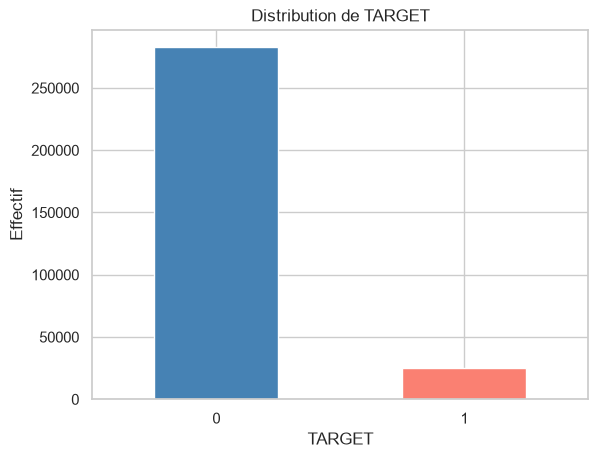

In [20]:
target_counts = train["TARGET"].value_counts().sort_index()
target_rate = train["TARGET"].mean()

print(target_counts)
print(f"Taux de défaut (TARGET=1) : {target_rate:.2%}")
print(f"Ratio classe majoritaire / minoritaire : {(1 - target_rate) / target_rate:.1f} : 1")

ax = target_counts.plot(kind="bar", color=["steelblue", "salmon"], rot=0)
ax.set_xlabel("TARGET")
ax.set_ylabel("Effectif")
ax.set_title("Distribution de TARGET")
plt.show()

## 3. Valeurs manquantes

Mesure du taux de NA par colonne et des co-absences entre colonnes.

- Le tableau **% NA** priorise les colonnes les plus incomplètes.
- **`msno.bar`** : complétude par colonne.
- **`msno.heatmap`** : corrélation des *absences* (si A est NA, B l’est-il aussi ?).

Constat principal repris en feature engineering (`fe_v1`) : le bloc logement manque souvent en groupe → flag `HOUSING_MISSING` ; `EXT_SOURCE_1` a beaucoup de NA (~56 %) mais est conservé (signal fort).


In [21]:
missing = (
    train.isna()
    .mean()
    .sort_values(ascending=False)
    .rename("pct_na")
    .to_frame()
)
missing["n_na"] = train.isna().sum()
missing_top = missing[missing["pct_na"] > 0].head(30)
display(missing_top.style.format({"pct_na": "{:.1%}"}))

print(f"Colonnes avec au moins 1 NA : {(missing['pct_na'] > 0).sum()} / {train.shape[1]}")

,pct_na,n_na
COMMONAREA_AVG,69.9%,214865
COMMONAREA_MODE,69.9%,214865
COMMONAREA_MEDI,69.9%,214865
NONLIVINGAPARTMENTS_MEDI,69.4%,213514
NONLIVINGAPARTMENTS_MODE,69.4%,213514
NONLIVINGAPARTMENTS_AVG,69.4%,213514
FONDKAPREMONT_MODE,68.4%,210295
LIVINGAPARTMENTS_AVG,68.4%,210199
LIVINGAPARTMENTS_MEDI,68.4%,210199
LIVINGAPARTMENTS_MODE,68.4%,210199


Colonnes avec au moins 1 NA : 67 / 122


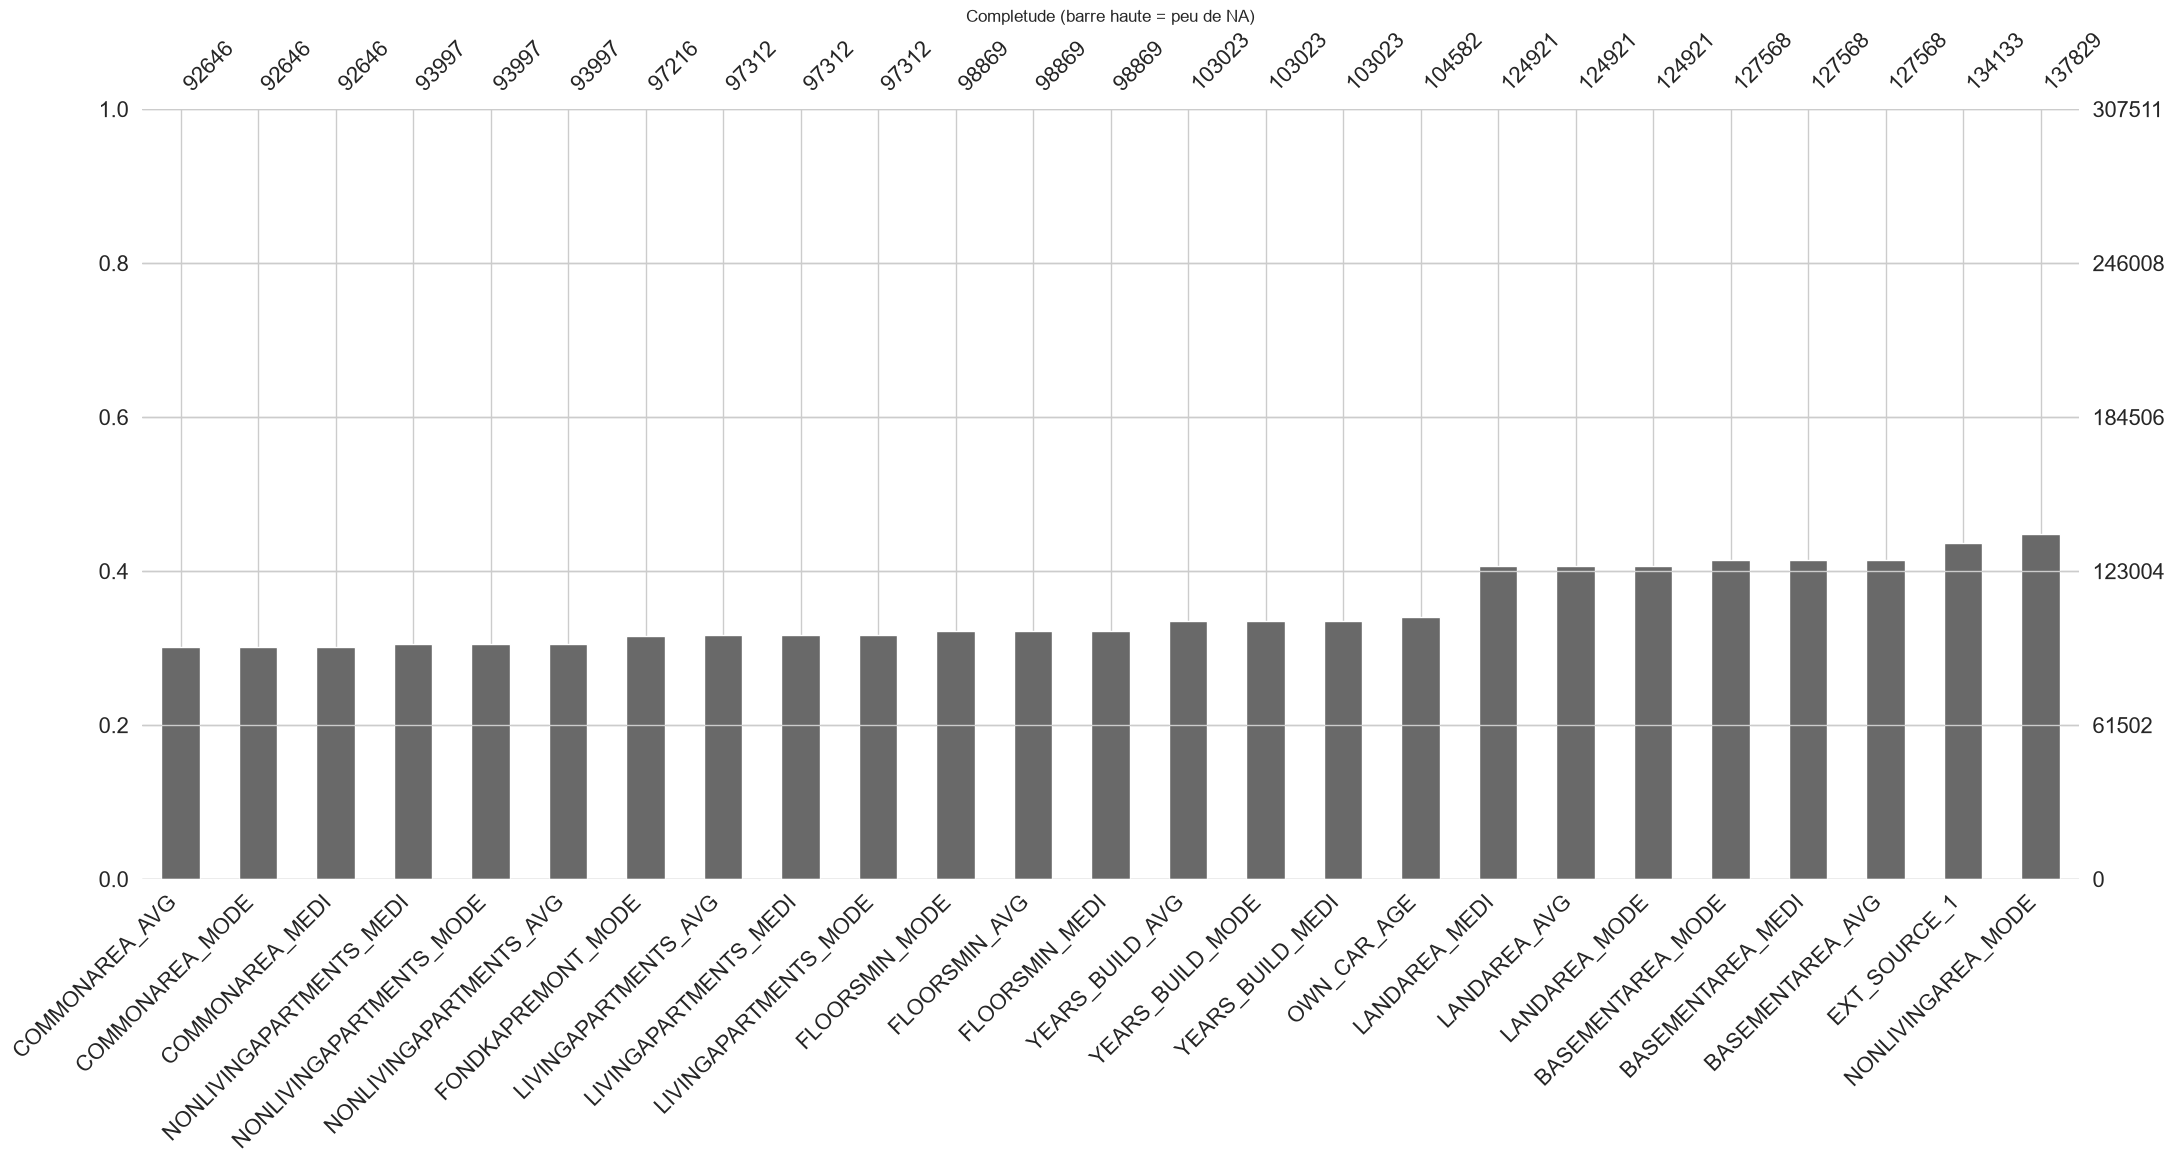

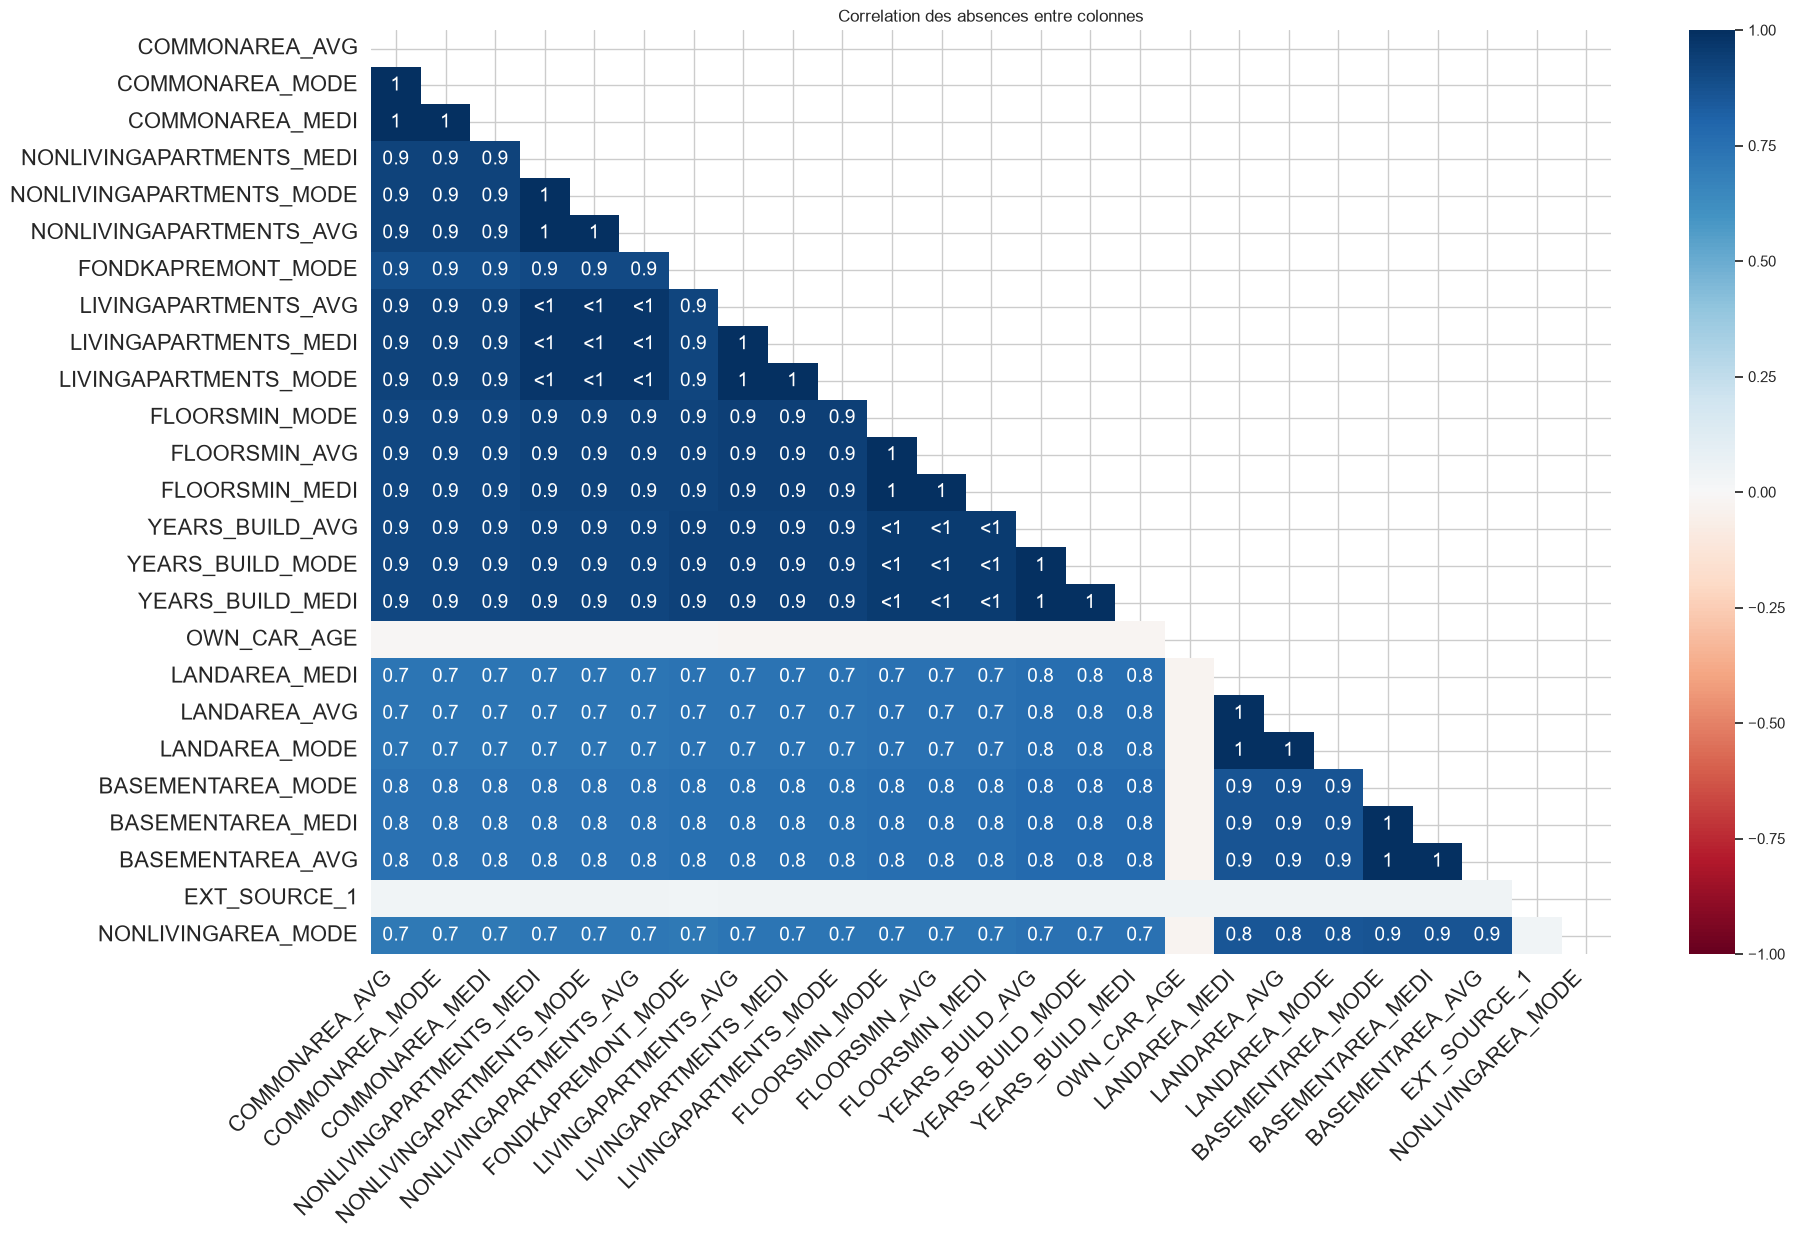

In [26]:
# Top colonnes avec NA (pas toute la table : trop de bruit)
cols_na = missing[missing["pct_na"] > 0].index.tolist()[:25]

# 1) Barres de completude : lisible
msno.bar(train[cols_na])
plt.title("Completude (barre haute = peu de NA)")
plt.show()

# 2) Correlation des NA : colonnes logement manquent souvent ensemble
msno.heatmap(train[cols_na])
plt.title("Correlation des absences entre colonnes")
plt.show()


### Heatmap Missingno

La heatmap ne mesure pas la corrélation entre *valeurs* (âge vs revenu), mais entre **absences** : « quand A est manquant, B l’est-il aussi ? ».

Sur ce dataset, les variables logement (`*_AVG` / `*_MODE` / `*_MEDI`) forment un bloc de NA très corrélé : souvent aucune info immeuble pour le client, plutôt qu’une colonne isolée. Cela justifie un traitement groupé (flag manquant) plutôt qu’une imputation colonne par colonne.


## 4. Premiers signaux univariés vs TARGET

Variables examinées : `EXT_SOURCE_*`, montants (`AMT_*`), âge / emploi.


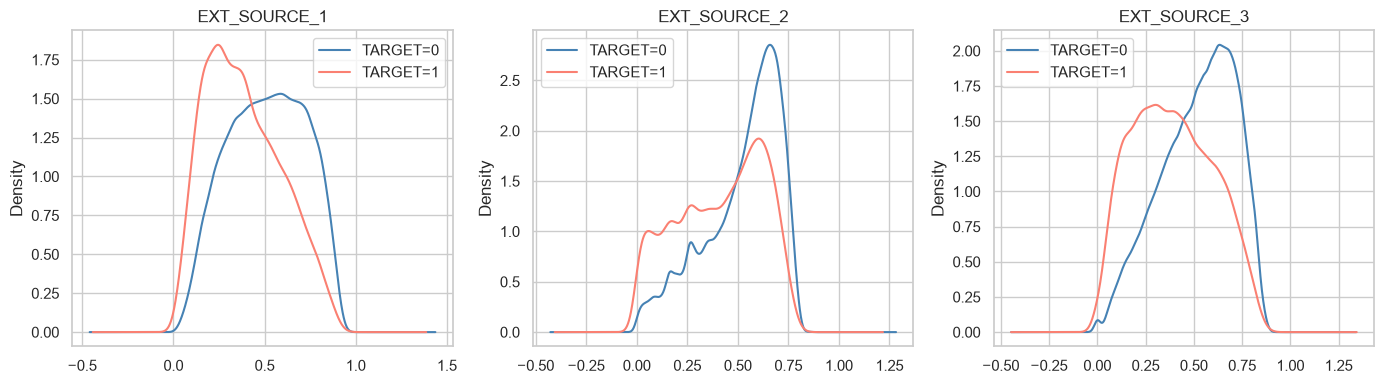

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    for t, color in [(0, "steelblue"), (1, "salmon")]:
        train.loc[train["TARGET"] == t, col].plot(
            kind="kde", ax=ax, color=color, label=f"TARGET={t}"
        )
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

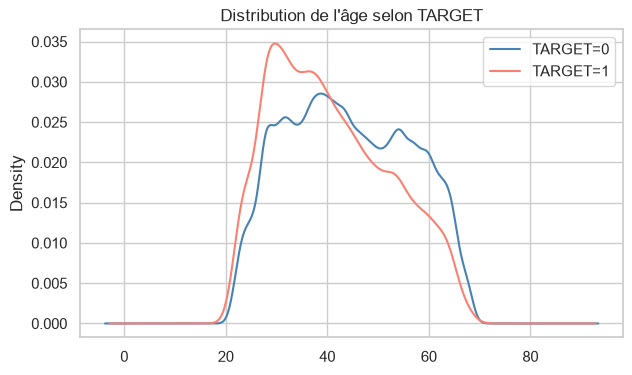

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
TARGET,,,
0,148500.0,517788.0,24876.0
1,135000.0,497520.0,25263.0


In [24]:
# Âge en années (DAYS_BIRTH est négatif = jours avant la demande)
train = train.copy()
train["AGE_YEARS"] = (-train["DAYS_BIRTH"]) / 365.25

fig, ax = plt.subplots(figsize=(7, 4))
for t, color in [(0, "steelblue"), (1, "salmon")]:
    train.loc[train["TARGET"] == t, "AGE_YEARS"].plot(
        kind="kde", ax=ax, color=color, label=f"TARGET={t}"
    )
ax.set_title("Distribution de l'âge selon TARGET")
ax.legend()
plt.show()

train.groupby("TARGET")[["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]].median()

## 5. Anomalie `DAYS_EMPLOYED`

Dans Home Credit, la valeur **365243** code une sentinelle (« sans emploi / non renseigné »), pas une ancienneté réelle (~18 % des lignes). En `fe_v1`, elle est remplacée par NaN avec un indicateur `DAYS_EMPLOYED_ANOMALY`.


count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
Valeur max: 365243
Part à la valeur max: 0.18007160719453938


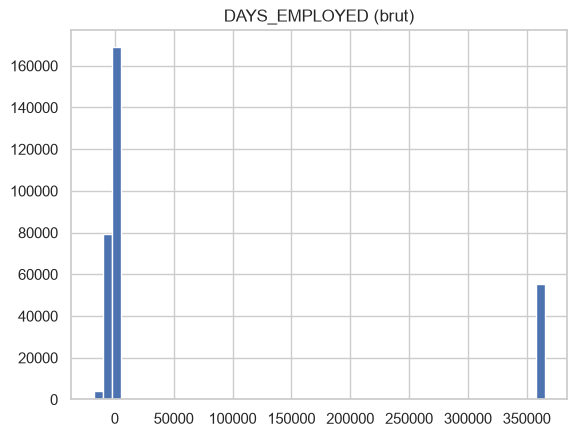

In [25]:
print(train["DAYS_EMPLOYED"].describe())
print("Valeur max:", train["DAYS_EMPLOYED"].max())
print(
    "Part à la valeur max:",
    (train["DAYS_EMPLOYED"] == train["DAYS_EMPLOYED"].max()).mean(),
)

train["DAYS_EMPLOYED"].hist(bins=50)
plt.title("DAYS_EMPLOYED (brut)")
plt.show()

## 6. Synthèse EDA (`application_train`)

| Question | Réponse |
|----------|---------|
| Taux de défaut | **8,07 %** (`TARGET=1` : 24 825 / 307 511). Ratio ≈ 11,4 : 1 — classes déséquilibrées. |
| Colonnes les plus NA | Bloc logement / immeuble (`COMMONAREA_*`, `NONLIVINGAPARTMENTS_*`, `LIVINGAPARTMENTS_*`, `FLOORSMIN_*`, `YEARS_BUILD_*`, etc. ≈ **66–70 %** NA). Les NA partent souvent en groupe (heatmap). `EXT_SOURCE_1` ≈ **56 %** NA, conservé. |
| Variables discriminantes | **`EXT_SOURCE_1/2/3`** : scores de risque externes normalisés (détail de formule non public). Moyennes plus basses si `TARGET=1` (ex. EXT_SOURCE_2 ≈ 0,41 vs 0,52). **Âge** : médiane un peu plus basse chez les défauts (~39 vs ~43 ans). |
| Anomalie traitée en FE | **`DAYS_EMPLOYED` = 365243** pour ~**18 %** des lignes → NaN + indicateur. |
| Suite réalisée | Feature engineering multi-tables industrialisé dans `src/features.py` + `src/build_dataset.py` (`fe_v1`) : flag logement, conservation des `EXT_SOURCE_*`, split stratifié 80/20 (seed 42) avant fit du preprocessing modèle. |
